# Day 6 lab: Applied Lab 6 — Advanced spreadsheet simulation

<p class="lead">
Build a decision model in Microsoft Excel for a car maker's electric-vehicle launch: a base profit model, a two-way Data Table that shows profit for 25 combinations of demand and cost, and a 50-trial Monte Carlo simulation that estimates the risk of a loss. Then use the model to weigh an ethical sourcing decision. This notebook gives the Excel steps and checks your numbers in Python.
</p>

*Adapted from the DATA 300 syllabus, Applied Lab 6 (Advanced spreadsheet simulation). Instructions rewritten for this classroom; the Data Table layout is corrected so that it works in Excel (see below).*

| | |
|---|---|
| **Graded** | Yes: **2%** of the course grade |
| **Outcomes** | CLO 4 and 5 |
| **Tools** | **Microsoft Excel** (the graded work); this notebook in JupyterLab to check your numbers |
| **You submit** | Two files in the **Applied Lab 6** drop-box on **GAP (Moodle)**: your workbook `YourLastName_DATA300_Lab6.xlsx` and your answers `YourLastName_Lab6_Answers.pdf` |
| **Deadline** | **Wednesday 18 November, 23:59 China Standard Time**, unless your facilitator says otherwise (see the [schedule](schedule.md)) |

> **Two corrections to the syllabus version**
>
> 1. **The Data Table's input cells must be on the same sheet as the table.** Excel refuses an input cell on another sheet with the message *"Input cell reference is not valid"*. The syllabus puts the table on a *What-If Analysis* sheet and its input cells on the *Base Model* sheet, which fails. In this version the What-If Analysis sheet has its own two **driver cells** for demand and cost, and the table uses those.
> 2. **The formula must sit in the top-left corner of the selected range.** In a two-way Data Table the corner cell holds the formula, the row values run to its right and the column values run below it. So the demand values go in **B3:B7**, directly under the formula in B2, and you select **B2:G7**.
>
> The results land in the same cells as in the syllabus (C3:G7), and every question is unchanged.

---

## The business scenario

You are a financial analyst at **EcoDrive Motors**, a **fictional** company preparing to launch an affordable electric vehicle (EV). Two things make the launch's profit uncertain: the cost of battery materials, and how many customers will buy. The board is also split on the battery supply chain:

| Option | Battery supplier | Extra cost |
|---|---|---|
| Cheaper | A supplier known for severe labour violations | none |
| Ethical | A supplier with ethical certification | **500 US dollars per vehicle** |

Your job: build an Excel model that projects the financial result, measures the risk of a loss, and shows what the ethical choice costs, so the board can decide knowingly. The plan uses the ethical supplier.

### Before you start

1. Open a **blank** Excel workbook and save it straight away as `YourLastName_DATA300_Lab6.xlsx` (with your real last name). Save again after each part.
2. Keep this notebook open next to Excel. Run its cells with **Shift + Enter**: each part ends with a Python check of the numbers your workbook should show.
3. Excel menus are given in English, with the Chinese labels where they help (labels may vary slightly by Excel version).

The setup cell loads the libraries and stores the plan's assumptions.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

BLUE, ORANGE, AQUA = "#2a78d6", "#eb6834", "#1baf7a"
GREY = "#c9c7c1"
INK = "#55534e"
plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e1",
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
})

# The plan's assumptions (Base Model sheet, B2:B6), in US dollars
DEMAND = 15_000          # B2 expected unit sales
PRICE = 35_000           # B3 sale price per vehicle
BASE_COST = 28_000       # B4 base manufacturing cost per vehicle
PREMIUM = 500            # B5 ethical sourcing premium per vehicle
OVERHEAD = 50_000_000    # B6 fixed overhead costs


def net_profit(demand, base_cost=BASE_COST, premium=PREMIUM, price=PRICE, overhead=OVERHEAD):
    """Net profit = revenue - variable costs - fixed overhead. Works on numbers and numpy arrays."""
    revenue = demand * price
    variable_costs = demand * (base_cost + premium)
    return revenue - variable_costs - overhead

---

## Part 1: The base (deterministic) model

A **deterministic** model gives one answer from one set of assumptions. It is the core that the Data Table and the simulation re-use, so every assumption goes in its own labelled cell and every formula refers to those cells.

> **In Excel: assumptions** (sheet *Base Model*)
>
> 1. Double-click the *Sheet1* tab and rename it **Base Model**.
> 2. Type these labels in column A and values in column B:
>
> | Cell | Label (column A) | Value (column B) |
> |---|---|---|
> | A1 | Scenario Assumptions | |
> | A2 / B2 | Expected Unit Sales (Demand) | 15000 |
> | A3 / B3 | EV Sale Price (Per Unit) | 35000 |
> | A4 / B4 | Base Manufacturing Cost (Per Unit) | 28000 |
> | A5 / B5 | Ethical Sourcing Premium (Per Unit) | 500 |
> | A6 / B6 | Fixed Overhead Costs | 50000000 |
>
> 3. Select **B3:B6** and format them as currency: **Home → Number Format → Currency** (开始 → 数字格式 → 货币).

> **In Excel: outputs**
>
> 1. In **D1:D4** type the labels *Financial Projections*, *Total Revenue*, *Total Variable Costs*, *Net Profit*.
> 2. In **E2** type `=B2*B3` (demand × price).
> 3. In **E3** type `=B2*(B4+B5)` (demand × (base cost + ethical premium)).
> 4. In **E4** type `=E2-E3-B6` (revenue − variable costs − fixed overhead).
> 5. Format **E2:E4** as currency, and widen the columns so nothing shows as `####`.
> 6. **Checkpoint:** E2, E3 and E4 must equal the Python output below.

In [2]:
revenue = DEMAND * PRICE
variable_costs = DEMAND * (BASE_COST + PREMIUM)
base_profit = net_profit(DEMAND)
print("Base Model checkpoint (US dollars)")
print(f"  E2 Total Revenue:         {revenue:>15,.0f}")
print(f"  E3 Total Variable Costs:  {variable_costs:>15,.0f}")
print(f"  E4 Net Profit:            {base_profit:>15,.0f}")

Base Model checkpoint (US dollars)
  E2 Total Revenue:             525,000,000
  E3 Total Variable Costs:      427,500,000
  E4 Net Profit:                 47,500,000


---

## Part 2: What-if analysis with a two-way Data Table

Demand and manufacturing cost are both uncertain. A **two-way Data Table** recalculates the net profit for every combination of five demand levels and five cost levels: 25 scenarios in one step.

### How the sheet is laid out

| Cells | Contents |
|---|---|
| **J2**, **J3** | The table's **driver cells** (its input cells): demand and base cost. They are on the same sheet as the table, which Excel requires |
| **B2** | The **corner formula**: net profit computed from J2 and J3, with price, premium and overhead taken from the Base Model |
| **C2:G2** | Five base-cost values, across the top |
| **B3:B7** | Five demand values, down the side |
| **C3:G7** | The 25 results that Excel fills in |

> **In Excel: build the Data Table** (sheet *What-If Analysis*)
>
> 1. Add a sheet (click **+** next to the tabs) and rename it **What-If Analysis**.
> 2. **Driver cells.** In **I1** type *Data Table driver cells*. In **I2** type *Demand (units)* and in **J2** type `15000`. In **I3** type *Base manufacturing cost per unit* and in **J3** type `28000`. Type plain numbers here, not formulas.
> 3. **Corner formula.** In **B2** type
>    `=J2*'Base Model'!$B$3-J2*(J3+'Base Model'!$B$5)-'Base Model'!$B$6`
>    This is the Base Model's net-profit formula, but with demand and cost taken from the driver cells.
> 4. **Check the link.** In **I5** type *Check: Base Model net profit* and in **J5** type `='Base Model'!E4`. B2 and J5 must show the same value. If they differ, compare your B2 formula with step 3.
> 5. **Cost values across the top:** in **C2:G2** type 24000, 26000, 28000, 30000, 32000.
> 6. **Demand values down the side:** in **B3:B7** type 5000, 10000, 15000, 20000, 25000. In **A3** you may type the label *Demand (units)*, and in **C1** *Base manufacturing cost per unit*.
> 7. Select the whole block **B2:G7** (the corner formula, the costs and the demands).
> 8. **Data → What-If Analysis → Data Table…** (数据 → 模拟分析 → 模拟运算表).
> 9. **Row input cell:** `J3` (the costs run along a row, so they replace the cost driver). **Column input cell:** `J2` (the demands run down a column, so they replace the demand driver). Click **OK**.
> 10. Select **C3:G7**, format it as currency, then **Home → Conditional Formatting → Color Scales** (开始 → 条件格式 → 色阶) and choose **Green - Yellow - Red**, so profits are green and losses red.

> **Why not point the table at the Base Model?**
>
> Excel's Data Table can only substitute values into cells on its **own** sheet. Clicking `'Base Model'!B4` in the dialog looks fine, but Excel then stops with *"Input cell reference is not valid"*. The driver cells solve this: the table changes J2 and J3, and the corner formula still takes price, premium and overhead from the Base Model, so a change on the Base Model (for example the premium in question 3) still flows into the table.

The Python cross-check below computes the same 25 scenarios. Your C3:G7 must match it exactly: there is nothing random in a Data Table.

Net profit (US dollars) by demand (rows) and base manufacturing cost per unit (columns)
base cost        24000        26000        28000        30000        32000
demand                                                                    
5000         2,500,000   -7,500,000  -17,500,000  -27,500,000  -37,500,000
10000       55,000,000   35,000,000   15,000,000   -5,000,000  -25,000,000
15000      107,500,000   77,500,000   47,500,000   17,500,000  -12,500,000
20000      160,000,000  120,000,000   80,000,000   40,000,000            0
25000      212,500,000  162,500,000  112,500,000   62,500,000   12,500,000


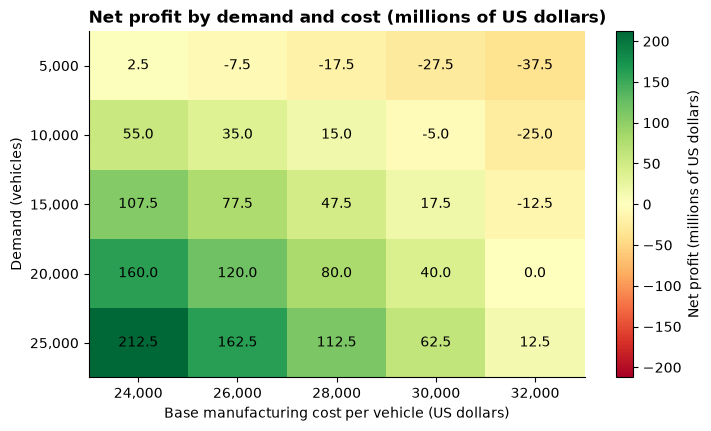

In [3]:
costs = [24_000, 26_000, 28_000, 30_000, 32_000]        # C2:G2
demands = [5_000, 10_000, 15_000, 20_000, 25_000]       # B3:B7
grid = pd.DataFrame([[net_profit(d, base_cost=c) for c in costs] for d in demands],
                    index=pd.Index(demands, name="demand"), columns=pd.Index(costs, name="base cost"))
print("Net profit (US dollars) by demand (rows) and base manufacturing cost per unit (columns)")
print(grid.map("{:,.0f}".format).to_string())

fig, ax = plt.subplots(figsize=(8, 4.5))
limit = np.abs(grid.values).max()
image = ax.imshow(grid.values / 1e6, cmap="RdYlGn", vmin=-limit / 1e6, vmax=limit / 1e6, aspect="auto")
ax.set_xticks(range(len(costs)), [f"{c:,}" for c in costs])
ax.set_yticks(range(len(demands)), [f"{d:,}" for d in demands])
for i in range(len(demands)):
    for j in range(len(costs)):
        ax.text(j, i, f"{grid.values[i, j] / 1e6:,.1f}", ha="center", va="center", color="black")
ax.grid(False)
ax.set_title("Net profit by demand and cost (millions of US dollars)")
ax.set_xlabel("Base manufacturing cost per vehicle (US dollars)")
ax.set_ylabel("Demand (vehicles)")
fig.colorbar(image, ax=ax, label="Net profit (millions of US dollars)")
plt.show()

The chart above is what your conditional formatting should look like: green where the launch makes money, red where it loses. Use your Data Table (and this check) for question 1.

---

## Part 3: Risk simulation (Monte Carlo)

The Data Table shows 25 chosen scenarios but says nothing about **how likely** each one is. A **Monte Carlo simulation** draws a random demand many times and records the profit each time. Here we run 50 trials: 50 "parallel futures" for the launch year. As in the syllabus, demand is equally likely to be any whole number from 8,000 to 22,000 vehicles, and every other assumption stays at its Base Model value.

> **In Excel: build the simulation** (sheet *Risk Simulation*)
>
> 1. Add a sheet and rename it **Risk Simulation**.
> 2. In **A1**, **B1**, **C1** type *Trial Number*, *Simulated Demand*, *Simulated Net Profit*.
> 3. Trial numbers: in **A2** type 1 and in **A3** type 2, select both and drag the fill handle down to **A51** (trials 1 to 50).
> 4. In **B2** type `=RANDBETWEEN(8000,22000)`: a random whole-number demand.
> 5. In **C2** type
>    `=(B2*'Base Model'!$B$3)-(B2*('Base Model'!$B$4+'Base Model'!$B$5))-'Base Model'!$B$6`
>    This is the Base Model's profit formula with the random demand. The `$` signs keep every row pointing at the same assumptions. (Cross-sheet references are fine here: only Data Tables need their input cells on the same sheet.)
> 6. Select **B2:C2** and drag the fill handle down to row **51**.
> 7. Summary box:
>
> | Label | Formula |
> |---|---|
> | **E1** Average Expected Profit | **F1** `=AVERAGE(C2:C51)` |
> | **E2** Minimum Profit (Worst Case) | **F2** `=MIN(C2:C51)` |
> | **E3** Maximum Profit (Best Case) | **F3** `=MAX(C2:C51)` |
> | **E4** Probability of Loss | **F4** `=COUNTIF(C2:C51,"<0")/50` |
>
> 8. Format **C2:C51** and **F1:F3** as currency and **F4** as a percentage (**Home → %**).
> 9. Press **F9** several times. The numbers change each time: Excel's `RANDBETWEEN` draws new values on every recalculation. Write down the average profit and the probability of a loss from **at least five** recalculations, for question 2.

Your Excel numbers will differ from the Python run below and from your neighbour's: Excel has no seed. The Python check uses a **fixed seed** so that everyone in the room sees the same reference run, then repeats the 50-trial simulation 1,000 times to show how much a 50-trial result can move when you press F9.

In [4]:
rng = np.random.default_rng(seed=2026)
N_TRIALS = 50

# One 50-trial run, like your Risk Simulation sheet
sim = pd.DataFrame({"Trial Number": np.arange(1, N_TRIALS + 1),
                    "Simulated Demand": rng.integers(8_000, 22_001, N_TRIALS)})   # = RANDBETWEEN(8000, 22000)
sim["Simulated Net Profit"] = net_profit(sim["Simulated Demand"])

print("First five trials of the reference run:")
print(sim.head().to_string(index=False, formatters={"Simulated Demand": "{:,}".format,
                                                    "Simulated Net Profit": "{:,.0f}".format}))
print("\nSummary box of the reference run (US dollars)")
print(f"  F1 Average Expected Profit:     {sim['Simulated Net Profit'].mean():>14,.0f}")
print(f"  F2 Minimum Profit (Worst Case): {sim['Simulated Net Profit'].min():>14,.0f}")
print(f"  F3 Maximum Profit (Best Case):  {sim['Simulated Net Profit'].max():>14,.0f}")
print(f"  F4 Probability of Loss:         {(sim['Simulated Net Profit'] < 0).mean():>14.0%}")

# What pressing F9 does: 1,000 separate 50-trial runs
runs = net_profit(rng.integers(8_000, 22_001, (1_000, N_TRIALS)))
run_means = runs.mean(axis=1)
run_loss = (runs < 0).mean(axis=1)
print("\nAcross 1,000 separate 50-trial runs (like pressing F9 1,000 times):")
print(f"  average profit ranged from {run_means.min():,.0f} to {run_means.max():,.0f}")
print(f"  middle 95% of runs: {np.quantile(run_means, 0.025):,.0f} to {np.quantile(run_means, 0.975):,.0f}")
print(f"  probability of loss ranged from {run_loss.min():.0%} to {run_loss.max():.0%}")

First five trials of the reference run:
 Trial Number Simulated Demand Simulated Net Profit
            1           19,926           79,519,000
            2           10,505           18,282,500
            3            8,369            4,398,500
            4           16,959           60,233,500
            5           13,117           35,260,500

Summary box of the reference run (US dollars)
  F1 Average Expected Profit:         46,552,430
  F2 Minimum Profit (Worst Case):      3,163,500
  F3 Maximum Profit (Best Case):      89,997,000
  F4 Probability of Loss:                     0%

Across 1,000 separate 50-trial runs (like pressing F9 1,000 times):
  average profit ranged from 34,143,150 to 59,023,200
  middle 95% of runs: 39,987,778 to 54,558,701
  probability of loss ranged from 0% to 0%


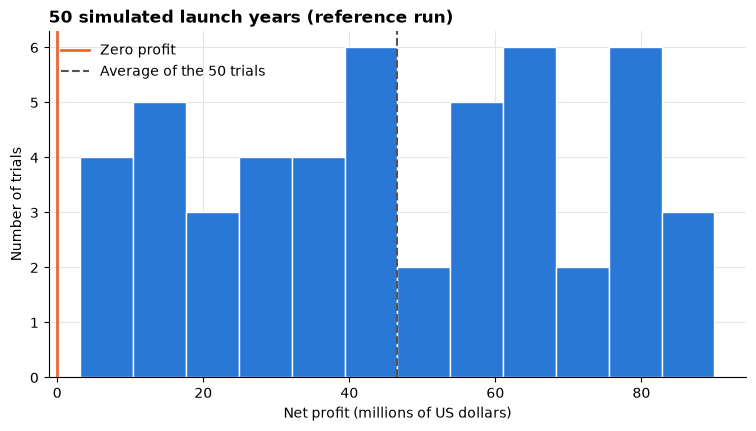

Break-even demand at the Base Model's cost and premium: 7,692 vehicles
Lowest demand the simulation can draw:                  8,000 vehicles


In [5]:
break_even_demand = OVERHEAD / (PRICE - BASE_COST - PREMIUM)

fig, ax = plt.subplots()
ax.hist(sim["Simulated Net Profit"] / 1e6, bins=12, color=BLUE, edgecolor="white")
ax.axvline(0, color=ORANGE, linewidth=2, label="Zero profit")
ax.axvline(sim["Simulated Net Profit"].mean() / 1e6, color=INK, linestyle="--", label="Average of the 50 trials")
ax.set_title("50 simulated launch years (reference run)")
ax.set_xlabel("Net profit (millions of US dollars)")
ax.set_ylabel("Number of trials")
ax.legend(frameon=False)
plt.show()

print(f"Break-even demand at the Base Model's cost and premium: {break_even_demand:,.0f} vehicles")
print("Lowest demand the simulation can draw:                  8,000 vehicles")

Compare the break-even demand above with the lowest demand the simulation can draw. That comparison explains the probability of a loss you see in Excel, whatever F9 gives you. Think about it for question 2, and also about what this simulation does **not** let vary.

---

## Part 4: Questions

Answer the four questions in a **Word document** (or another editor that saves PDF). Put your name and student ID at the top, number your answers 1–4, and quote the numbers you use, with units. Write in complete sentences.

| # | Outcome | Question |
|---|---|---|
| **1** | CLO 4 | **Break-even under a cost shock.** Supply shortages push the base manufacturing cost to 32,000 US dollars per vehicle. Using your Data Table, what is the smallest demand EcoDrive must reach to avoid a loss? Show how you confirmed it with a calculation (fixed overhead ÷ profit per vehicle). |
| **2** | CLO 4 | **How risky is the launch?** Press F9 several times on the Risk Simulation sheet. Report the probability of a loss and the average expected profit you observed (a range is fine), and explain how risky the launch looks and why. |
| **3** | CLO 5 | **The ethical dilemma.** On the Base Model, change the Ethical Sourcing Premium (B5) from 500 to **0**: this is the cheaper supplier with severe labour violations. (a) By how much does net profit rise? (b) As the analytics manager, write a **3–4 sentence** recommendation to the board for **keeping** the 500-dollar premium even though it lowers immediate profit. Consider long-term brand reputation, the people affected, and corporate responsibility. Then set B5 back to **500**. |
| **4** | CLO 5 | **The societal value of BI tools.** How does a spreadsheet simulation like this help EcoDrive bring an affordable EV to market **responsibly**? Why is it dangerous, financially and for society, to set prices and plans from a single best-case scenario instead of simulating uncertainty? |

> **Writing tips**
>
> Lead with the answer, then the evidence: *"At a cost of 32,000 dollars, EcoDrive must sell at least … vehicles, because …"*. In question 3, use today's lecture: put a number on the ethical choice, then weigh what the spreadsheet does not contain (fines, boycotts, import rules, workers' welfare). In question 4, name who else carries the risk of a bad launch.

---

## Part 5: Save and submit

1. On the Base Model, check that **B5 is back to 500**.
2. Check the three sheets are named **Base Model**, **What-If Analysis** and **Risk Simulation**, and save the workbook as **`YourLastName_DATA300_Lab6.xlsx`**.
3. Save your answers as PDF: **File → Save As → PDF** (文件 → 另存为 → PDF), named **`YourLastName_Lab6_Answers.pdf`**.
4. Log in to **GAP (Moodle)**, open the **DATA 300: Applied Lab 6** drop-box, upload **both** files and click **Submit** by **23:59 China Standard Time today**.

This lab has two separate files, so there is nothing to combine. If you add screenshots of your sheets to the answers, paste them into the Word document before saving the PDF; to join PDFs you already have, see [Combining PDFs without internet](setup.md#combining-pdfs-without-internet).

---

## Checklist before you upload

- [ ] Base Model: E4 matches the Part 1 checkpoint, and B5 is 500.
- [ ] What-If Analysis: B2 equals the Base Model's net profit; C3:G7 match the Part 2 check exactly; the colour scale shows losses in red.
- [ ] Risk Simulation: 50 trials in rows 2–51; the summary box F1:F4 works; F4 is a percentage.
- [ ] Four numbered answers with numbers and units; question 3 has both parts.
- [ ] Files named `YourLastName_DATA300_Lab6.xlsx` and `YourLastName_Lab6_Answers.pdf`, both uploaded to the Applied Lab 6 drop-box on GAP (Moodle).

## How it is marked

The lab uses the course's Lab 6 rubric: **CLO 4** (developing predictive models such as spreadsheet simulations to project outcomes, 40 points), **CLO 5** (evaluating BI tools in a case and writing managerial recommendations that consider ethical and societal contexts, 40 points), **professional formatting** (10 points) and **clear academic writing** (10 points). In practice: a working workbook with correct values, a break-even answer that is confirmed by calculation, an honest reading of the simulation, and a reasoned ethical recommendation.

---

## Going further (not graded)

The syllabus simulation lets only **demand** vary. In reality the base manufacturing cost is uncertain too: that is exactly what worried the board. Suppose the cost per vehicle follows a normal distribution with mean 28,000 and standard deviation 1,500 dollars.

In Excel, add a column to the Risk Simulation sheet: in **D1** *Simulated Base Cost*, in **D2** `=NORM.INV(RAND(),28000,1500)`, fill down to row 51, and change C2 to use **D2** instead of `'Base Model'!$B$4`. Press F9: what happens to the probability of a loss?

The cell below runs the same idea with 10,000 trials (more trials give a steadier estimate, as you saw on Day 5).

In [6]:
rng = np.random.default_rng(seed=7)
N = 10_000
demand_draws = rng.integers(8_000, 22_001, N)
for label, cost_draws in [("demand varies, cost fixed at 28,000", np.full(N, BASE_COST)),
                          ("demand varies, cost ~ normal(28,000, 1,500)", rng.normal(28_000, 1_500, N))]:
    profits = net_profit(demand_draws, base_cost=cost_draws)
    print(f"{label:<46} average {profits.mean():>13,.0f}   P(loss) {(profits < 0).mean():>6.1%}   "
          f"P5 {np.quantile(profits, 0.05):>13,.0f}")

demand varies, cost fixed at 28,000            average    47,449,074   P(loss)   0.0%   P5     6,855,175
demand varies, cost ~ normal(28,000, 1,500)    average    47,437,440   P(loss)   6.3%   P5    -1,996,400


Two more ideas to try in Excel:

1. **Goal Seek** for question 1: on the Base Model, set B4 to 32000, then **Data → What-If Analysis → Goal Seek** (单变量求解) with *Set cell* `E4`, *To value* `0`, *By changing cell* `B2`. Then press **Ctrl + Z** to undo, and set B4 back to 28000.
2. **More trials:** extend the Risk Simulation to 1,000 rows and change the 50 in F4 to `COUNT(C2:C1001)`. Does the average expected profit still move as much when you press F9?

> **Stuck?**
>
> *"Input cell reference is not valid"*: your row or column input cell is on another sheet; use J3 and J2 on the What-If Analysis sheet. *Every cell of the table shows the same number*: the corner formula in B2 does not use J2 and J3. *The numbers do not match the Part 2 check*: the row and column input cells are swapped (row input J3, column input J2). *`#NAME?`*: a function name or sheet name is mistyped; sheet names with spaces need single quotes, as in `'Base Model'!B3`. For anything else, take a screenshot and ask your facilitator.